# Paso 1: Filtro Inicial de Acciones

### Fase 1.1: Descarga y Filtrado de Acciones por Volumen Promedio

In [1]:
import pandas as pd
import yfinance as yf
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# 1. Lista de muestra de tickers para analizar
tickers_muestra = [
    'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'TSLA', 'META', 'NVDA', 'JPM', 'JNJ', 'V',
    'PG', 'UNH', 'HD', 'MA', 'BAC', 'DIS', 'CVX', 'PEP', 'CSCO', 'XOM',
    'ABBV', 'MRK', 'KO', 'COST', 'MCD', 'WMT', 'CRM', 'PFE', 'TMO', 'ABT',
    'DHR', 'ACN', 'NKE', 'LIN', 'NEE', 'TXN', 'BMY', 'WFC', 'HON', 'AMGN',
    'QCOM', 'PM', 'LOW', 'INTC', 'IBM', 'ORCL', 'BA', 'SPGI', 'GS', 'C',
    'CAT', 'MMM', 'DE', 'RTX', 'LMT', 'GE', 'BLK', 'MS', 'AXP', 'SCHW',
    'T', 'VZ', 'CMCSA', 'INTU', 'GILD', 'CVS', 'MDT', 'SYK', 'ISRG', 'SYY',
    'BDX', 'BSX', 'ZTS', 'EW', 'VRTX', 'PLD', 'AMT', 'CCI', 'PSA', 'EQIX',
    'DUK', 'SO', 'D', 'AEP', 'SRE', 'EXC', 'XEL', 'ED', 'PEG', 'WEC'
]

# 2. Descarga vectorizada en lote (incluyendo SPY como benchmark real del mercado)
download_list = sorted(list(set(tickers_muestra + ['SPY'])))
print(f"Descargando datos vectorizados para {len(download_list)} activos (incluyendo benchmark SPY)...")

raw_market_data = yf.download(download_list, period="5y", auto_adjust=False, progress=False)

# 3. Filtrar acciones con historial suficiente (>= 252 días) y volumen promedio >= 1,000,000
acciones_validas = {}
min_volume = 1_000_000

for ticker in download_list:
    try:
        t_df = pd.DataFrame({
            'Date': raw_market_data.index.copy(),
            'Open': raw_market_data['Open'][ticker],
            'High': raw_market_data['High'][ticker],
            'Low': raw_market_data['Low'][ticker],
            'Close': raw_market_data['Close'][ticker],
            'Volume': raw_market_data['Volume'][ticker]
        }).reset_index(drop=True).dropna()

        if len(t_df) >= 252:
            vol_prom = t_df['Volume'].mean()
            # SPY se preserva como benchmark; las demás deben superar el filtro de volumen
            if ticker == 'SPY' or vol_prom >= min_volume:
                acciones_validas[ticker.lower()] = t_df
    except Exception as error:
        print(f"Error procesando {ticker}: {error}")

total_acciones = len([k for k in acciones_validas.keys() if k != 'spy'])
print(f"Se encontraron {total_acciones} acciones válidas (+ benchmark SPY) de {len(tickers_muestra)} analizadas.")
print("Muestra de acciones válidas encontradas:", list(acciones_validas.keys())[:15])


Descargando datos vectorizados para 91 activos (incluyendo benchmark SPY)...
Se encontraron 87 acciones válidas (+ benchmark SPY) de 90 analizadas.
Muestra de acciones válidas encontradas: ['aapl', 'abbv', 'abt', 'acn', 'aep', 'amgn', 'amt', 'amzn', 'axp', 'ba', 'bac', 'bdx', 'bmy', 'bsx', 'c']


### Fase 1.2: Consolidación de Precios de Cierre y Retornos Diarios

In [2]:
import numpy as np
import pandas as pd

# Consolidar los precios de cierre ajustados de las acciones válidas
lista_precios = []
for ticker, df_accion in acciones_validas.items():
    df_temp = df_accion[['Date', 'Close']].copy()
    df_temp['Date'] = pd.to_datetime(df_temp['Date'])
    df_temp = df_temp.rename(columns={'Close': ticker})
    lista_precios.append(df_temp.set_index('Date'))

# Unir todos los dataframes en uno solo alineado temporalmente
df_precios_unidos = pd.concat(lista_precios, axis=1, join='inner')

# Benchmark real de mercado (SPY)
if 'spy' in df_precios_unidos.columns:
    df_precios_unidos['Market'] = df_precios_unidos['spy']
else:
    df_precios_unidos['Market'] = df_precios_unidos.mean(axis=1)

# Calcular retornos diarios
retornos_diarios = df_precios_unidos.pct_change().dropna()

# Definir retornos_activos (excluyendo el benchmark Market y spy) de forma global
retornos_activos = retornos_diarios.drop(columns=['Market', 'spy'], errors='ignore')

print(f"Dimensiones de precios consolidados: {df_precios_unidos.shape}")
print(f"Total activos analizados (excluyendo Market): {len(retornos_activos.columns)}")
print("\nPrimeras filas de los retornos diarios:")
display(retornos_diarios.head())


Dimensiones de precios consolidados: (1253, 89)
Total activos analizados (excluyendo Market): 87

Primeras filas de los retornos diarios:


,aapl,abbv,abt,acn,aep,amgn,amt,amzn,axp,ba,...,v,vrtx,vz,wec,wfc,wmt,xel,xom,zts,Market
Date,,,,,,,,,,,,,,,,,,,,,
2021-11-19,0.016976,-0.007090,-0.006268,-0.002670,0.006762,0.010097,0.007801,-0.005273,-0.015152,-0.057734,...,-0.012148,-0.013645,-0.007416,0.004327,-0.021643,-0.005379,0.011969,-0.046219,0.003946,-0.001788
2021-11-22,0.002927,-0.005076,-0.012457,-0.017551,0.011034,-0.016256,-0.012836,-0.028287,-0.015213,-0.019754,...,-0.026287,-0.007546,0.013370,0.011047,0.031135,0.016785,0.018587,0.013845,-0.009230,-0.002815
2021-11-23,0.002422,0.027929,-0.006227,-0.007157,0.000119,0.008879,0.016962,0.002091,-0.000292,-0.003668,...,0.014879,0.029477,0.004074,-0.005682,0.021057,0.007114,-0.007088,0.026337,-0.003031,0.001326
2021-11-24,0.003284,-0.001851,0.004740,0.004630,-0.005812,-0.002738,0.013282,0.000103,0.004448,0.007029,...,0.023981,-0.003265,-0.001739,-0.003407,-0.001751,0.005007,-0.004405,0.005544,-0.002191,0.002670
2021-11-26,-0.031678,-0.018119,0.006476,-0.024202,-0.015151,-0.014120,-0.009831,-0.021185,-0.086184,-0.054084,...,-0.027552,-0.014229,0.002710,-0.016760,-0.056129,-0.011192,-0.012052,-0.035129,-0.017251,-0.022303


# Paso 2: Análisis Fundamental y Modelos Financieros

### Fase 2.1: Cálculo del CAPM y Beta de Hamada

In [3]:
# Definir variables financieras de tasa libre de riesgo y retorno de mercado
try:
    import pandas_datareader.data as web
    rf_data = web.DataReader('DGS10', 'fred').dropna()
    tasa_libre_riesgo_anual = float(rf_data.iloc[-1].values[0]) / 100
    print(f"Tasa libre de riesgo obtenida de FRED (DGS10): {tasa_libre_riesgo_anual:.4f}")
except Exception:
    tasa_libre_riesgo_anual = 0.04
    print(f"Tasa libre de riesgo fijada por defecto: {tasa_libre_riesgo_anual:.4f}")

retorno_mercado_anual = retornos_diarios['Market'].mean() * 252
varianza_mercado = retornos_diarios['Market'].var() * 252

metricas_acciones = []
np.random.seed(42)  # Para reproducibilidad en la simulación didáctica de D/E
tasa_impuestos = 0.21

for ticker in retornos_activos.columns:
    # Calcular Beta Histórica contra el Benchmark real (Market/SPY)
    covarianza_activo_mercado = retornos_diarios[ticker].cov(retornos_diarios['Market']) * 252
    beta_apalancada = covarianza_activo_mercado / varianza_mercado

    # Retorno Esperado usando CAPM tradicional
    retorno_esperado_capm = tasa_libre_riesgo_anual + beta_apalancada * (retorno_mercado_anual - tasa_libre_riesgo_anual)

    # Simular una relación Deuda/Capital (D/E) para demostración de desapalancamiento
    relacion_deuda_capital = np.random.uniform(0.1, 1.5)

    # Beta Desapalancada de Hamada (Beta_U)
    beta_desapalancada = beta_apalancada / (1 + (1 - tasa_impuestos) * relacion_deuda_capital)

    # Retorno Esperado ajustado por Beta de Hamada
    retorno_esperado_hamada = tasa_libre_riesgo_anual + beta_desapalancada * (retorno_mercado_anual - tasa_libre_riesgo_anual)

    metricas_acciones.append({
        'Activo': ticker.upper(),
        'Beta_Apalancada': beta_apalancada,
        'Retorno_Esperado_CAPM': retorno_esperado_capm,
        'Relacion_D_E': relacion_deuda_capital,
        'Beta_Hamada_Desapalancada': beta_desapalancada,
        'Retorno_Esperado_Hamada': retorno_esperado_hamada
    })

# Convertir las métricas a DataFrame
df_metricas_fundamentales = pd.DataFrame(metricas_acciones).set_index('Activo')
print(f"--- Análisis de CAPM y Beta de Hamada (Mostrando primeros 10 de {len(df_metricas_fundamentales)} activos) ---")
display(df_metricas_fundamentales.head(10))


Tasa libre de riesgo obtenida de FRED (DGS10): 0.0512
--- Análisis de CAPM y Beta de Hamada (Mostrando primeros 10 de 87 activos) ---


,Beta_Apalancada,Retorno_Esperado_CAPM,Relacion_D_E,Beta_Hamada_Desapalancada,Retorno_Esperado_Hamada
Activo,,,,,
AAPL,1.143725,0.114545,0.624356,0.765934,0.093621
ABBV,0.286254,0.067054,1.431000,0.134361,0.058642
ABT,0.486066,0.078121,1.124792,0.257370,0.065454
ACN,0.880868,0.099987,0.938122,0.505921,0.079220
AEP,0.287153,0.067104,0.318426,0.229437,0.063907
AMGN,0.434721,0.075277,0.318392,0.347351,0.070438
AMT,0.443815,0.075781,0.181317,0.388208,0.072701
AMZN,1.478931,0.133110,1.312647,0.726037,0.091411
AXP,1.147062,0.114730,0.941561,0.657782,0.087631


# Paso 3: Análisis Técnico con Indicadores

### Fase 3.1: Medias Móviles, RSI, MACD y Oscilador Estocástico

Total acciones saliendo de sobreventa o en zona de rebote: 22


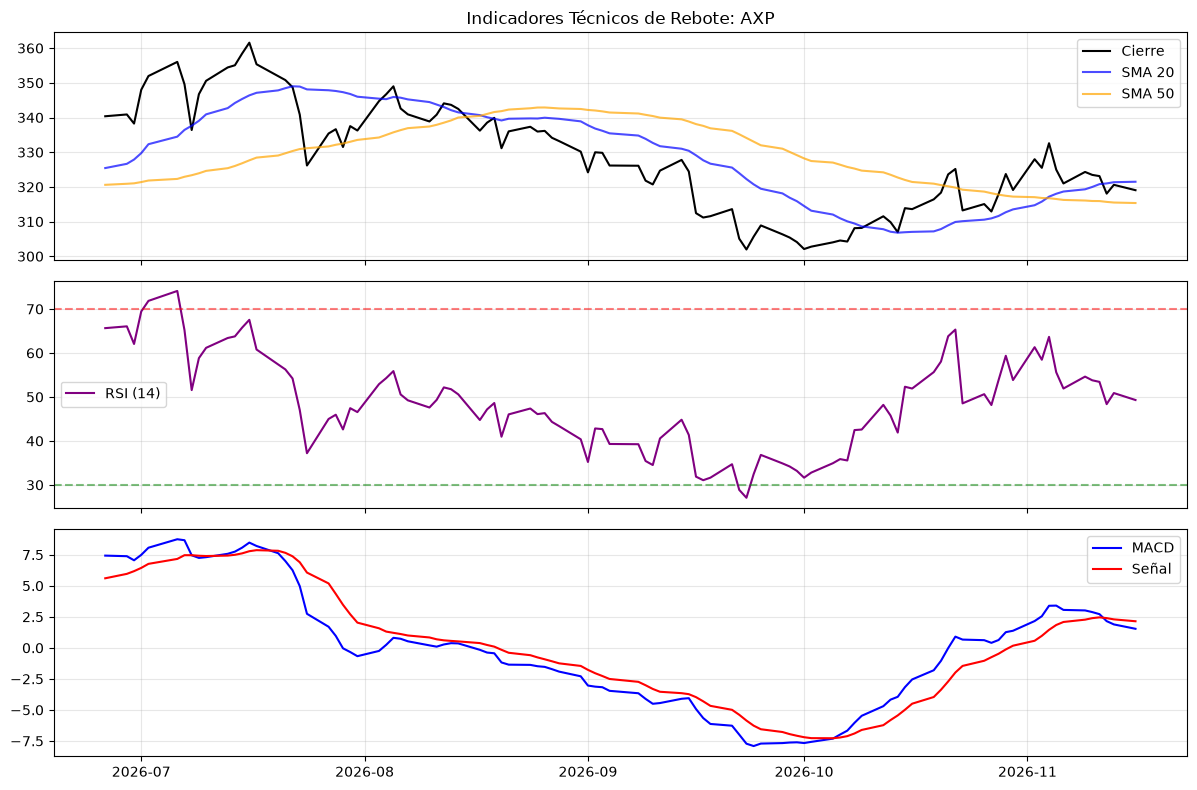

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Función robusta para RSI con suavizado exponencial de Wilder
def calcular_rsi_wilder(serie, periodo=14):
    delta = serie.diff()
    ganancia = delta.where(delta > 0, 0.0)
    perdida = -delta.where(delta < 0, 0.0)
    avg_gain = ganancia.ewm(alpha=1/periodo, min_periods=periodo, adjust=False).mean()
    avg_loss = perdida.ewm(alpha=1/periodo, min_periods=periodo, adjust=False).mean()
    rs = avg_gain / avg_loss
    return 100 - (100 / (1 + rs))

# Escáner: Buscar acciones saliendo de sobreventa
acciones_sobreventa = []
indicadores_sobreventa = {}

for ticker, df_accion in acciones_validas.items():
    if ticker == 'spy':
        continue
    df_tecnico = df_accion.copy()
    df_tecnico['Date'] = pd.to_datetime(df_tecnico['Date'])
    df_tecnico = df_tecnico.sort_values('Date').set_index('Date')

    # RSI 14 (Wilder)
    df_tecnico['RSI_14'] = calcular_rsi_wilder(df_tecnico['Close'], 14)

    # Oscilador Estocástico
    minimo_14 = df_tecnico['Low'].rolling(window=14).min()
    maximo_14 = df_tecnico['High'].rolling(window=14).max()
    df_tecnico['Estocastico_K'] = 100 * ((df_tecnico['Close'] - minimo_14) / (maximo_14 - minimo_14))
    df_tecnico['Estocastico_D'] = df_tecnico['Estocastico_K'].rolling(window=3).mean()

    # MACD
    ema_12 = df_tecnico['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = df_tecnico['Close'].ewm(span=26, adjust=False).mean()
    df_tecnico['MACD'] = ema_12 - ema_26
    df_tecnico['MACD_Senal'] = df_tecnico['MACD'].ewm(span=9, adjust=False).mean()

    # Medias Móviles
    df_tecnico['SMA_20'] = df_tecnico['Close'].rolling(window=20).mean()
    df_tecnico['SMA_50'] = df_tecnico['Close'].rolling(window=50).mean()

    # Condición de sobreventa reciente: RSI < 35 o Estocástico %K < 25 en los últimos 5 días
    ultimos_dias = df_tecnico.tail(5)
    if (ultimos_dias['RSI_14'] < 35).any() or (ultimos_dias['Estocastico_K'] < 25).any():
        acciones_sobreventa.append(ticker)
        indicadores_sobreventa[ticker] = df_tecnico

print(f"Total acciones saliendo de sobreventa o en zona de rebote: {len(acciones_sobreventa)}")

# Graficar un ejemplo representativo si se encontraron acciones
if len(acciones_sobreventa) > 0:
    ejemplo = acciones_sobreventa[0]
    df_ejemplo = indicadores_sobreventa[ejemplo].tail(100) # Últimas 100 velas

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

    ax1.plot(df_ejemplo.index, df_ejemplo['Close'], label='Cierre', color='black')
    ax1.plot(df_ejemplo.index, df_ejemplo['SMA_20'], label='SMA 20', color='blue', alpha=0.7)
    ax1.plot(df_ejemplo.index, df_ejemplo['SMA_50'], label='SMA 50', color='orange', alpha=0.7)
    ax1.set_title(f'Indicadores Técnicos de Rebote: {ejemplo.upper()}')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    ax2.plot(df_ejemplo.index, df_ejemplo['RSI_14'], label='RSI (14)', color='purple')
    ax2.axhline(70, color='red', linestyle='--', alpha=0.5)
    ax2.axhline(30, color='green', linestyle='--', alpha=0.5)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    ax3.plot(df_ejemplo.index, df_ejemplo['MACD'], label='MACD', color='blue')
    ax3.plot(df_ejemplo.index, df_ejemplo['MACD_Senal'], label='Señal', color='red')
    ax3.legend()
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


### Fase 3.2: Categorización de Activos por Volatilidad y Direccionalidad
En esta fase clasificamos dinámicamente las acciones del universo analizado de acuerdo con dos dimensiones clave:
1. **Volatilidad Anualizada**: Clasificadas en *Alta Volatilidad* o *Baja Volatilidad* utilizando el valor medio de volatilidad como umbral.
2. **Direccionalidad (RSI)**: Clasificadas en tendencia *Alcista* (RSI de 14 días > 50) o *Bajista* (RSI de 14 días <= 50).

In [5]:
# 1. Calcular volatilidad histórica anualizada para todos los activos
volatilidades = retornos_activos.std() * np.sqrt(252)
umbral_volatilidad = volatilidades.median()

# 2. Calcular el último RSI_14 (Wilder) para cada activo
rsis_actuales = {}
for ticker in retornos_activos.columns:
    df_accion = acciones_validas[ticker]
    precios_close = df_accion.sort_values('Date')['Close']
    rsi_serie = calcular_rsi_wilder(precios_close, 14)
    rsis_actuales[ticker] = rsi_serie.dropna().iloc[-1] if len(rsi_serie.dropna()) > 0 else 50.0

# 3. Clasificar según condiciones cuantitativas
categorias_acciones = []
for ticker in volatilidades.index:
    vol = volatilidades[ticker]
    rsi = rsis_actuales.get(ticker, 50.0)

    # Determinar categoría de volatilidad
    cat_vol = "Alta Volatilidad" if vol > umbral_volatilidad else "Baja Volatilidad"

    # Determinar dirección de la tendencia
    cat_dir = "Alcista" if rsi > 50 else "Bajista"

    categorias_acciones.append({
        'Activo': ticker.upper(),
        'Volatilidad_Anualizada': vol,
        'RSI_Actual': rsi,
        'Categoria_Volatilidad': cat_vol,
        'Direccionalidad': cat_dir,
        'Cuadrante': f"{cat_vol} - {cat_dir}"
    })

df_categorizacion = pd.DataFrame(categorias_acciones).set_index('Activo')
print("--- Clasificación Cuantitativa de Activos (Muestra de 10) ---")
display(df_categorizacion.sort_values(by='Cuadrante').head(10))
print("\nDistribución por cuadrantes:")
print(df_categorizacion['Cuadrante'].value_counts())


--- Clasificación Cuantitativa de Activos (Muestra de 10) ---


,Volatilidad_Anualizada,RSI_Actual,Categoria_Volatilidad,Direccionalidad,Cuadrante
Activo,,,,,
AAPL,0.281443,56.999703,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
ACN,0.332757,54.736993,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
AMT,0.275028,59.268868,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
CCI,0.288093,61.301691,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
CMCSA,0.278479,69.243981,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
DHR,0.291862,50.837536,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
DIS,0.294512,65.936037,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
EW,0.327902,80.100680,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista
GE,0.312849,53.356288,Alta Volatilidad,Alcista,Alta Volatilidad - Alcista



Distribución por cuadrantes:
Cuadrante
Baja Volatilidad - Alcista    32
Alta Volatilidad - Bajista    24
Alta Volatilidad - Alcista    19
Baja Volatilidad - Bajista    12
Name: count, dtype: int64


# Paso 4: Análisis Econométrico y Riesgo/Rendimiento

### Fase 4.1: Retornos, Volatilidad, Matriz de Correlación y Cointegración

--- Métricas Econométricas de Activos Individuales (Primeros 10 de 87) ---


,Retorno_Medio_Anual,Varianza_Anual,Volatilidad_Anual,Ratio_Sharpe
AAPL,0.201305,0.079210,0.281443,0.533340
ABBV,0.213829,0.055683,0.235972,0.689187
ABT,-0.007416,0.054475,0.233399,-0.251142
ACN,-0.025602,0.110727,0.332757,-0.230805
AEP,0.110254,0.041036,0.202574,0.291516
AMGN,0.196012,0.062889,0.250777,0.577456
AMT,-0.023835,0.075641,0.275028,-0.272826
AMZN,0.134114,0.134974,0.367388,0.225685
AXP,0.162482,0.086024,0.293299,0.379417
BA,0.004433,0.137034,0.370181,-0.126335


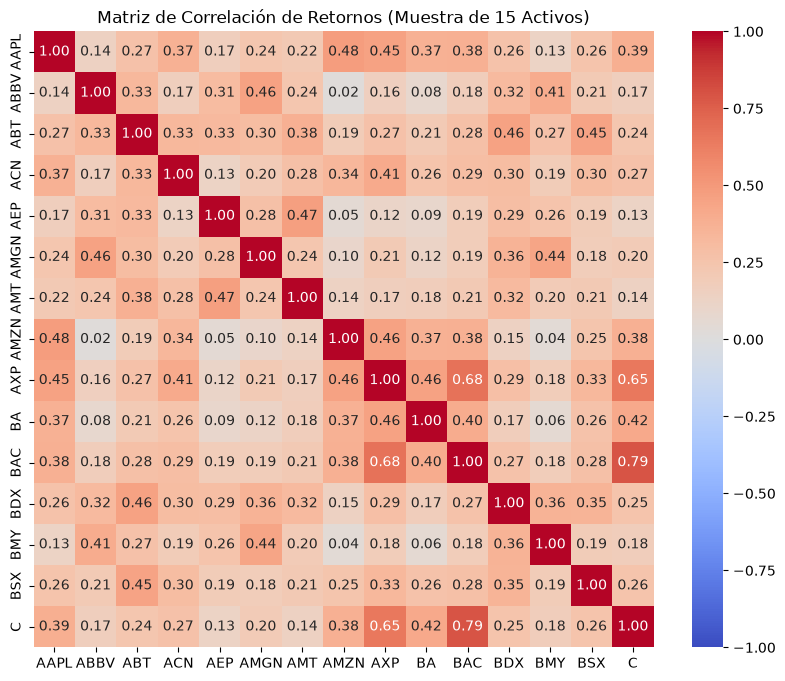


--- Test de Cointegración: AAPL vs ABBV ---
p-valor: 0.0282
Existe evidencia de que los activos están cointegrados (relación estacionaria a largo plazo).


In [6]:
import seaborn as sns
from statsmodels.tsa.stattools import coint

# Métricas de riesgo y rendimiento anualizadas
retorno_medio_anual = retornos_activos.mean() * 252
varianza_anual = retornos_activos.var() * 252
volatilidad_anual = retornos_activos.std() * np.sqrt(252)

# Ratio de Sharpe individual
ratio_sharpe = (retorno_medio_anual - tasa_libre_riesgo_anual) / volatilidad_anual

# Resumen de métricas econométricas
df_econometrico = pd.DataFrame({
    'Retorno_Medio_Anual': retorno_medio_anual,
    'Varianza_Anual': varianza_anual,
    'Volatilidad_Anual': volatilidad_anual,
    'Ratio_Sharpe': ratio_sharpe
})
df_econometrico.index = [t.upper() for t in df_econometrico.index]

print(f"--- Métricas Econométricas de Activos Individuales (Primeros 10 de {len(df_econometrico)}) ---")
display(df_econometrico.head(10))

# Matriz de covarianza y correlación
matriz_cov = retornos_activos.cov() * 252
matriz_corr = retornos_activos.corr()

# Visualizar mapa de calor de correlaciones para una muestra representativa de 15 activos
muestra_corr = matriz_corr.iloc[:15, :15]
muestra_corr.columns = [c.upper() for c in muestra_corr.columns]
muestra_corr.index = [i.upper() for i in muestra_corr.index]

plt.figure(figsize=(10, 8))
sns.heatmap(muestra_corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Retornos (Muestra de 15 Activos)')
plt.show()

# Test de Cointegración para el primer par de activos
simbolos = list(retornos_activos.columns)
if len(simbolos) >= 2:
    activo1, activo2 = simbolos[0], simbolos[1]
    puntos_precio1 = df_precios_unidos[activo1]
    puntos_precio2 = df_precios_unidos[activo2]
    p_valor = coint(puntos_precio1, puntos_precio2)[1]

    print(f"\n--- Test de Cointegración: {activo1.upper()} vs {activo2.upper()} ---")
    print(f"p-valor: {p_valor:.4f}")
    if p_valor < 0.05:
        print("Existe evidencia de que los activos están cointegrados (relación estacionaria a largo plazo).")
    else:
        print("No hay evidencia sólida de cointegración (p >= 0.05).")


# Paso 5: Construcción y Análisis de Portafolios

### Fase 5.1: Portafolio Equiponderado

In [7]:
# Crear pesos iguales para todos los activos
num_activos = len(retornos_activos.columns)
pesos_iguales = np.array([1 / num_activos] * num_activos)

# Calcular rendimiento del portafolio equiponderado
rendimiento_portafolio = np.dot(pesos_iguales, retorno_medio_anual)

# Calcular varianza y volatilidad del portafolio
varianza_portafolio = np.dot(pesos_iguales.T, np.dot(matriz_cov, pesos_iguales))
volatilidad_portafolio = np.sqrt(varianza_portafolio)

# Sharpe Ratio
ratio_sharpe_portafolio = (rendimiento_portafolio - tasa_libre_riesgo_anual) / volatilidad_portafolio

print("--- Estadísticas del Portafolio Equiponderado (1/N) ---")
print(f"Total de activos en el portafolio: {num_activos}")
print(f"Rendimiento Anualizado Esperado: {rendimiento_portafolio:.2%}")
print(f"Volatilidad Anualizada: {volatilidad_portafolio:.2%}")
print(f"Ratio de Sharpe: {ratio_sharpe_portafolio:.4f}")


--- Estadísticas del Portafolio Equiponderado (1/N) ---
Total de activos en el portafolio: 87
Rendimiento Anualizado Esperado: 9.51%
Volatilidad Anualizada: 14.28%
Ratio de Sharpe: 0.3077


# Paso 6: Optimización de Portafolio con SciPy

### Fase 6.1: Frontera Eficiente, GMV y Máximo Sharpe

In [8]:
import scipy.optimize as sco

# Función para calcular estadísticas del portafolio dado unos pesos
def calcular_estadisticas_portafolio(pesos):
    pesos = np.array(pesos)
    ret = np.dot(pesos, retorno_medio_anual)
    vol = np.sqrt(np.dot(pesos.T, np.dot(matriz_cov, pesos)))
    sharpe = (ret - tasa_libre_riesgo_anual) / vol
    return np.array([ret, vol, sharpe])

# Funciones objetivo a minimizar
def minimizar_sharpe(pesos):
    return -calcular_estadisticas_portafolio(pesos)[2]

def minimizar_volatilidad(pesos):
    return calcular_estadisticas_portafolio(pesos)[1]

# Restricciones institucionales:
# 1. Suma de pesos = 1
# 2. Pesos entre 0% y 35% por activo (evita sobreconcentración)
restricciones = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
limites = tuple((0, 0.35) for _ in range(num_activos))
pesos_iniciales = num_activos * [1. / num_activos,]

# 1. Portafolio de Máximo Sharpe
opt_sharpe = sco.minimize(minimizar_sharpe, pesos_iniciales, method='SLSQP', bounds=limites, constraints=restricciones)
pesos_max_sharpe = opt_sharpe.x
stats_max_sharpe = calcular_estadisticas_portafolio(pesos_max_sharpe)

# 2. Portafolio de Mínima Varianza Global (GMV)
opt_gmv = sco.minimize(minimizar_volatilidad, pesos_iniciales, method='SLSQP', bounds=limites, constraints=restricciones)
pesos_gmv = opt_gmv.x
stats_gmv = calcular_estadisticas_portafolio(pesos_gmv)

# Tabla comparativa de portafolios
df_comparacion_portafolios = pd.DataFrame({
    'Portafolio Equiponderado': [rendimiento_portafolio, volatilidad_portafolio, ratio_sharpe_portafolio],
    'Mínima Varianza (GMV)': stats_gmv,
    'Máximo Sharpe (Tope 35%)': stats_max_sharpe
}, index=['Rendimiento Esperado', 'Volatilidad Anual', 'Ratio de Sharpe'])

print("--- Comparativa de Portafolios Optimizados ---")
display(df_comparacion_portafolios.map(lambda x: f"{x:.4f}"))

# Mostrar activos con asignación relevante (> 0.5%)
df_pesos = pd.DataFrame({
    'Equiponderado': pesos_iguales,
    'GMV': pesos_gmv,
    'Max_Sharpe': pesos_max_sharpe
}, index=[t.upper() for t in retornos_activos.columns])

print("\n--- Activos con asignación relevante (> 0.5%) en GMV o Max Sharpe ---")
activos_activos = df_pesos[(df_pesos['GMV'] > 0.005) | (df_pesos['Max_Sharpe'] > 0.005)]
display(activos_activos.map(lambda x: f"{x*100:.2f}%"))


--- Comparativa de Portafolios Optimizados ---


,Portafolio Equiponderado,Mínima Varianza (GMV),Máximo Sharpe (Tope 35%)
Rendimiento Esperado,0.0951,0.1245,0.2756
Volatilidad Anual,0.1428,0.1135,0.1533
Ratio de Sharpe,0.3077,0.6456,1.4640



--- Activos con asignación relevante (> 0.5%) en GMV o Max Sharpe ---


,Equiponderado,GMV,Max_Sharpe
ABBV,1.15%,1.29%,12.26%
BMY,1.15%,0.93%,0.00%
CAT,1.15%,2.18%,0.00%
CSCO,1.15%,2.11%,0.00%
CVS,1.15%,0.83%,0.00%
CVX,1.15%,3.62%,0.00%
DUK,1.15%,4.39%,0.00%
ED,1.15%,5.94%,0.00%
EW,1.15%,2.17%,0.00%
GE,1.15%,0.00%,20.42%


# Paso 7: Simulaciones de Monte Carlo y Recomendaciones Finales

### Fase 7.1: Simulación de Portafolios por Monte Carlo

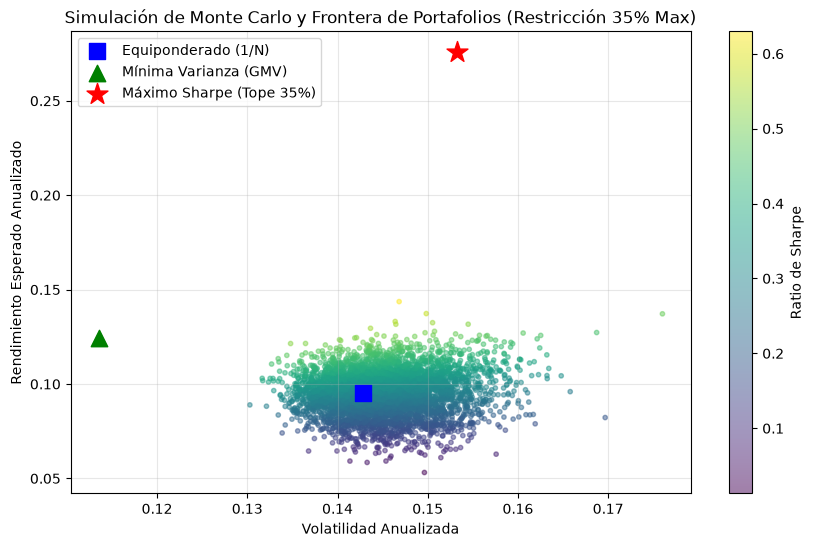

In [9]:
num_simulaciones = 5000
resultados_simulados = np.zeros((3, num_simulaciones))

np.random.seed(42)
sim_count = 0
while sim_count < num_simulaciones:
    # Generar pesos aleatorios
    pesos_aleatorios = np.random.exponential(scale=1.0, size=num_activos)
    pesos_aleatorios /= np.sum(pesos_aleatorios)

    # Asegurar que se respete la cota máxima del 35% por activo
    if (pesos_aleatorios <= 0.35).all():
        stats_aleatorias = calcular_estadisticas_portafolio(pesos_aleatorios)
        resultados_simulados[:, sim_count] = stats_aleatorias
        sim_count += 1

# Graficar la simulación de Monte Carlo
plt.figure(figsize=(10, 6))
plt.scatter(resultados_simulados[1, :], resultados_simulados[0, :], c=resultados_simulados[2, :], cmap='viridis', marker='o', s=10, alpha=0.5)
plt.colorbar(label='Ratio de Sharpe')

# Marcar los portafolios clave
plt.scatter(volatilidad_portafolio, rendimiento_portafolio, color='blue', marker='s', s=120, label='Equiponderado (1/N)')
plt.scatter(stats_gmv[1], stats_gmv[0], color='green', marker='^', s=140, label='Mínima Varianza (GMV)')
plt.scatter(stats_max_sharpe[1], stats_max_sharpe[0], color='red', marker='*', s=250, label='Máximo Sharpe (Tope 35%)')

plt.title('Simulación de Monte Carlo y Frontera de Portafolios (Restricción 35% Max)')
plt.xlabel('Volatilidad Anualizada')
plt.ylabel('Rendimiento Esperado Anualizado')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()


# Paso 8: Cuadro de Mando Automatizado y Selección Top 5
### Fase 8.1: Ranking Multifactores y Selección del Top 5 de Acciones
Puntuación general multifactores basada en:
* **35% Ratio de Sharpe** (Retorno ajustado al riesgo).
* **25% Rendimiento Anualizado**.
* **25% Control de Drawdown** (Menor caída histórica máxima).
* **15% Baja Volatilidad** (Resiliencia ante oscilaciones bruscas).

In [10]:
import pandas as pd
import numpy as np

# 1. Preparar las métricas de cada acción
metricas = []

for ticker in retornos_activos.columns:
    # Rendimiento y Sharpe ya calculados en el entorno
    rendimiento = retorno_medio_anual[ticker]
    sharpe = ratio_sharpe[ticker]
    vol = volatilidad_anual[ticker]

    # Calcular Control Drawdown (calculando Max Drawdown primero)
    precios = df_precios_unidos[ticker]
    maximos_historicos = precios.cummax()
    drawdowns = (precios - maximos_historicos) / maximos_historicos
    max_drawdown = drawdowns.min()  # suele ser un valor negativo
    # Convertimos a Control Drawdown: cuanto menor sea la caída máxima, mayor será este valor
    control_drawdown = 1 + max_drawdown

    # Baja Volatilidad (inversa de la volatilidad, para que a menor vol, mayor puntaje)
    baja_volatilidad = 1 / vol if vol > 0 else 0

    metricas.append({
        'Ticker': ticker,
        'Rendimiento': rendimiento,
        'Sharpe': sharpe,
        'Control_Drawdown': control_drawdown,
        'Baja_Volatilidad': baja_volatilidad
    })

df_metricas = pd.DataFrame(metricas)

# 2. Normalizar métricas (Min-Max) para tenerlas en una escala de 0 a 1
def min_max_norm(serie):
    if serie.max() == serie.min():
        return 1.0
    return (serie - serie.min()) / (serie.max() - serie.min())

df_metricas['Norm_Sharpe'] = min_max_norm(df_metricas['Sharpe'])
df_metricas['Norm_Rendimiento'] = min_max_norm(df_metricas['Rendimiento'])
df_metricas['Norm_Drawdown'] = min_max_norm(df_metricas['Control_Drawdown'])
df_metricas['Norm_Baja_Vol'] = min_max_norm(df_metricas['Baja_Volatilidad'])

# 3. Calcular Score General
# 35% Sharpe + 25% Rendimiento + 25% Control Drawdown + 15% Baja Volatilidad
df_metricas['Score_General'] = (
    0.35 * df_metricas['Norm_Sharpe'] +
    0.25 * df_metricas['Norm_Rendimiento'] +
    0.25 * df_metricas['Norm_Drawdown'] +
    0.15 * df_metricas['Norm_Baja_Vol']
)

# 4. Obtener las top 5 y generar el reporte
top_5 = df_metricas.sort_values(by='Score_General', ascending=False).head(5)

print("=" * 70)
print("                INFORME AUTOMATIZADO: TOP 5 ACCIONES")
print("=" * 70)
print("Fórmula:\nScore General = 35% Sharpe + 25% Rendimiento + 25% Control Drawdown + 15% Baja Volatilidad\n")

reporte = top_5[['Ticker', 'Rendimiento', 'Sharpe', 'Control_Drawdown', 'Baja_Volatilidad', 'Score_General']].copy()
reporte.rename(columns={
    'Rendimiento': 'Retorno Anual',
    'Control_Drawdown': 'Ctrl Drawdown',
    'Baja_Volatilidad': 'Factor Baja Vol'
}, inplace=True)

display(reporte.style.format({
    'Retorno Anual': '{:.2%}',
    'Sharpe': '{:.2f}',
    'Ctrl Drawdown': '{:.2%}',
    'Factor Baja Vol': '{:.2f}',
    'Score_General': '{:.4f}'
}).hide(axis='index'))


                INFORME AUTOMATIZADO: TOP 5 ACCIONES
Fórmula:
Score General = 35% Sharpe + 25% Rendimiento + 25% Control Drawdown + 15% Baja Volatilidad



Ticker,Retorno Anual,Sharpe,Ctrl Drawdown,Factor Baja Vol,Score_General
ge,38.05%,1.05,59.22%,3.20,0.7934
wmt,22.54%,0.77,73.99%,4.39,0.7871
ko,13.22%,0.48,79.11%,5.89,0.7736
abbv,21.38%,0.69,75.74%,4.24,0.7703
xom,23.01%,0.67,79.35%,3.74,0.7695


### Fase 8.2: Análisis Integral del Portafolio Top 5
Evaluación CAPM, matriz de correlación econométrica, optimización de cartera Max Sharpe y simulación Monte Carlo especializada exclusivamente sobre los 5 activos seleccionados.

EJECUTANDO ANÁLISIS INTEGRAL PARA EL TOP 5: ['ge', 'wmt', 'ko', 'abbv', 'xom']

--- 1. Análisis CAPM y Beta (Top 5) ---


,Activo,Beta,Retorno_Esperado_CAPM
0,ge,1.068579,0.110383
1,wmt,0.395271,0.073092
2,ko,0.235880,0.064264
3,abbv,0.286254,0.067054
4,xom,0.372037,0.071805



--- 2. Análisis Técnico Rápido del Líder: GE ---


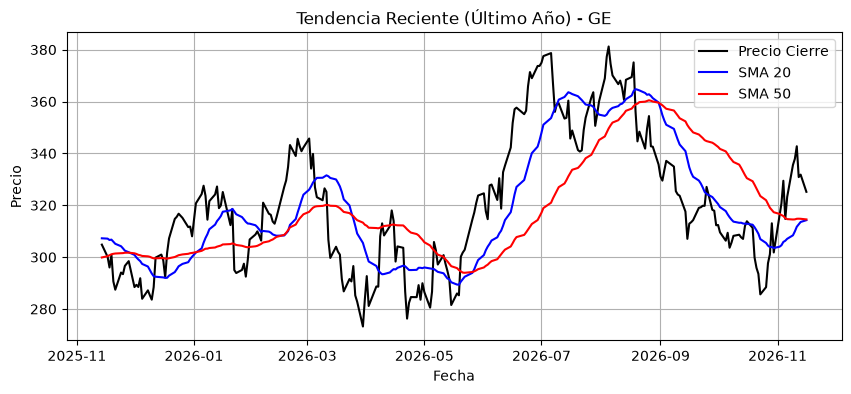


--- 3. Matriz de Correlación Econométrica (Top 5) ---


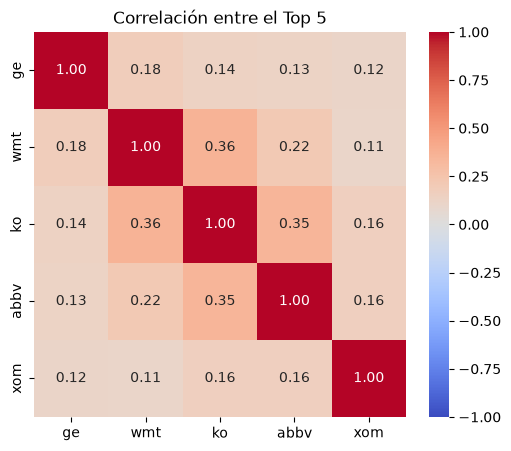


--- 4. Optimización de Portafolio (Top 5) ---
Distribución Óptima (Máximo Sharpe Ratio):
  - GE: 33.47%
  - WMT: 25.27%
  - KO: 0.00%
  - ABBV: 20.74%
  - XOM: 20.51%

Retorno Esperado del Portafolio: 27.59%
Volatilidad del Portafolio: 16.50%
Sharpe Ratio: 1.3614

--- 5. Simulación de Monte Carlo (Top 5) ---


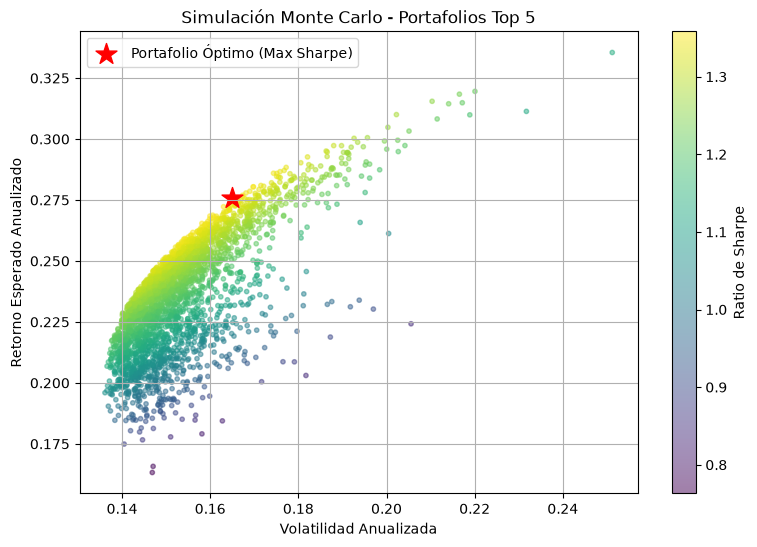

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.optimize as sco
from statsmodels.tsa.stattools import coint

# 0. Extraer los top 5 tickers
top_tickers = top_5['Ticker'].tolist()
print("=" * 70)
print(f"EJECUTANDO ANÁLISIS INTEGRAL PARA EL TOP 5: {top_tickers}")
print("=" * 70)

# 1. Filtrar retornos y calcular métricas base
retornos_top5 = retornos_diarios[top_tickers]
retorno_medio_top5 = retornos_top5.mean() * 252
matriz_cov_top5 = retornos_top5.cov() * 252

# 2. CAPM y Beta
print("\n--- 1. Análisis CAPM y Beta (Top 5) ---")
metricas_capm_top5 = []
for ticker in top_tickers:
    cov_mercado = retornos_diarios[ticker].cov(retornos_diarios['Market']) * 252
    beta = cov_mercado / (retornos_diarios['Market'].var() * 252)
    ret_esperado = tasa_libre_riesgo_anual + beta * (retorno_mercado_anual - tasa_libre_riesgo_anual)
    metricas_capm_top5.append({'Activo': ticker, 'Beta': beta, 'Retorno_Esperado_CAPM': ret_esperado})
display(pd.DataFrame(metricas_capm_top5))

# 3. Análisis Técnico del Líder (la acción #1)
lider = top_tickers[0]
print(f"\n--- 2. Análisis Técnico Rápido del Líder: {lider.upper()} ---")
df_lider = acciones_validas[lider].copy()
df_lider['Date'] = pd.to_datetime(df_lider['Date'])
df_lider = df_lider.set_index('Date').sort_index()
df_lider['SMA_20'] = df_lider['Close'].rolling(20).mean()
df_lider['SMA_50'] = df_lider['Close'].rolling(50).mean()

plt.figure(figsize=(10, 4))
plt.plot(df_lider.index[-252:], df_lider['Close'].tail(252), label='Precio Cierre', color='black')
plt.plot(df_lider.index[-252:], df_lider['SMA_20'].tail(252), label='SMA 20', color='blue')
plt.plot(df_lider.index[-252:], df_lider['SMA_50'].tail(252), label='SMA 50', color='red')
plt.title(f'Tendencia Reciente (Último Año) - {lider.upper()}')
plt.xlabel('Fecha')
plt.ylabel('Precio')
plt.legend()
plt.grid(True)
plt.show()

# 4. Matriz de Correlación Top 5
print("\n--- 3. Matriz de Correlación Econométrica (Top 5) ---")
plt.figure(figsize=(6, 5))
sns.heatmap(retornos_top5.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Correlación entre el Top 5')
plt.show()

# 5. Optimización de Portafolio (Max Sharpe)
print("\n--- 4. Optimización de Portafolio (Top 5) ---")
num_activos_top5 = len(top_tickers)

def calc_stats_top5(pesos):
    pesos = np.array(pesos)
    ret = np.dot(pesos, retorno_medio_top5)
    vol = np.sqrt(np.dot(pesos.T, np.dot(matriz_cov_top5, pesos)))
    sharpe = (ret - tasa_libre_riesgo_anual) / vol
    return np.array([ret, vol, sharpe])

def min_sharpe_top5(pesos):
    return -calc_stats_top5(pesos)[2]

# Restricciones y límites (0 a 100% por ser portafolio concentrado)
restricciones_top5 = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
limites_top5 = tuple((0, 1.0) for _ in range(num_activos_top5))
pesos_ini_top5 = num_activos_top5 * [1. / num_activos_top5,]

opt_sharpe_top5 = sco.minimize(min_sharpe_top5, pesos_ini_top5, method='SLSQP', bounds=limites_top5, constraints=restricciones_top5)
stats_opt = calc_stats_top5(opt_sharpe_top5.x)

print("Distribución Óptima (Máximo Sharpe Ratio):")
for t, p in zip(top_tickers, opt_sharpe_top5.x):
    print(f"  - {t.upper()}: {p:.2%}")
print(f"\nRetorno Esperado del Portafolio: {stats_opt[0]:.2%}")
print(f"Volatilidad del Portafolio: {stats_opt[1]:.2%}")
print(f"Sharpe Ratio: {stats_opt[2]:.4f}")

# 6. Simulación Monte Carlo
print("\n--- 5. Simulación de Monte Carlo (Top 5) ---")
num_sims = 3000
res_sims = np.zeros((3, num_sims))
for i in range(num_sims):
    w = np.random.random(num_activos_top5)
    w /= np.sum(w)
    s = calc_stats_top5(w)
    res_sims[:, i] = s

plt.figure(figsize=(9, 6))
plt.scatter(res_sims[1], res_sims[0], c=res_sims[2], cmap='viridis', marker='o', s=10, alpha=0.5)
plt.colorbar(label='Ratio de Sharpe')
plt.scatter(stats_opt[1], stats_opt[0], color='red', marker='*', s=250, label='Portafolio Óptimo (Max Sharpe)')
plt.title('Simulación Monte Carlo - Portafolios Top 5')
plt.xlabel('Volatilidad Anualizada')
plt.ylabel('Retorno Esperado Anualizado')
plt.legend()
plt.grid(True)
plt.show()

### Fase 8.3: Análisis Técnico Detallado de las Acciones Seleccionadas
Inspección técnica individual con Medias Móviles (SMA 20/50), RSI de Wilder (14) y MACD para los componentes del Top 5 durante el último año de negociación.

          ANÁLISIS TÉCNICO DETALLADO: TOP 5 ACCIONES

Generando gráficos para: GE


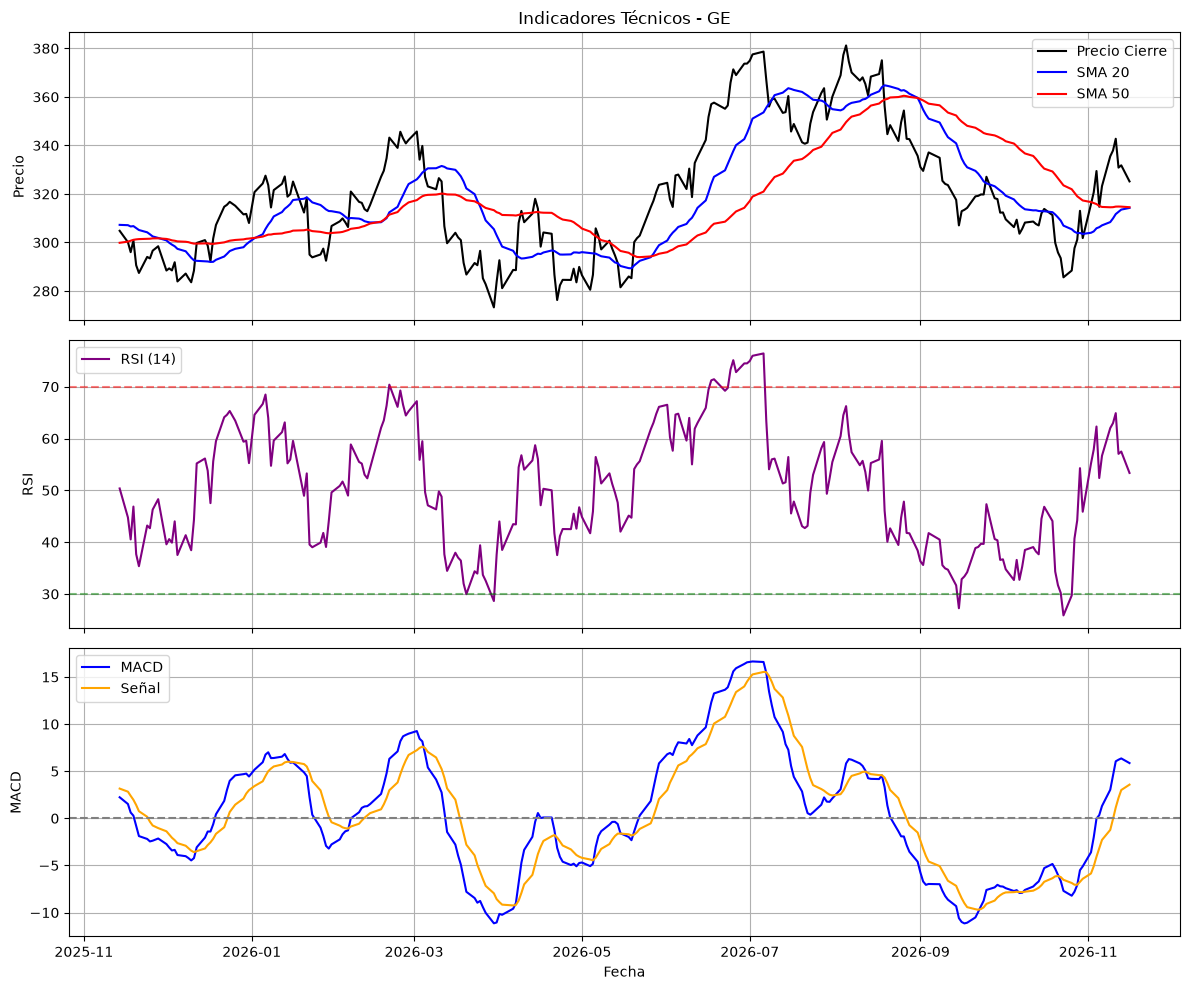


Generando gráficos para: WMT


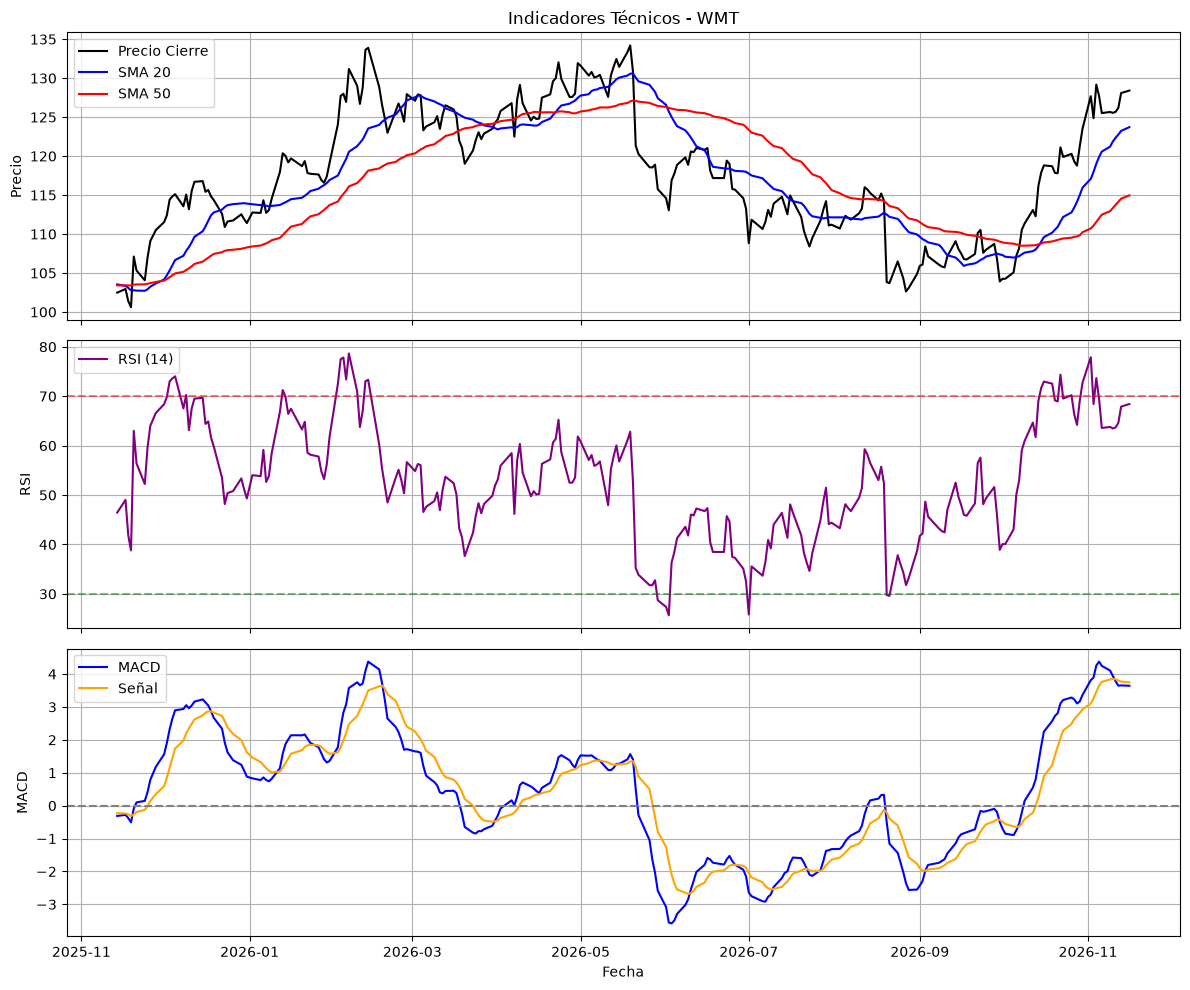


Generando gráficos para: KO


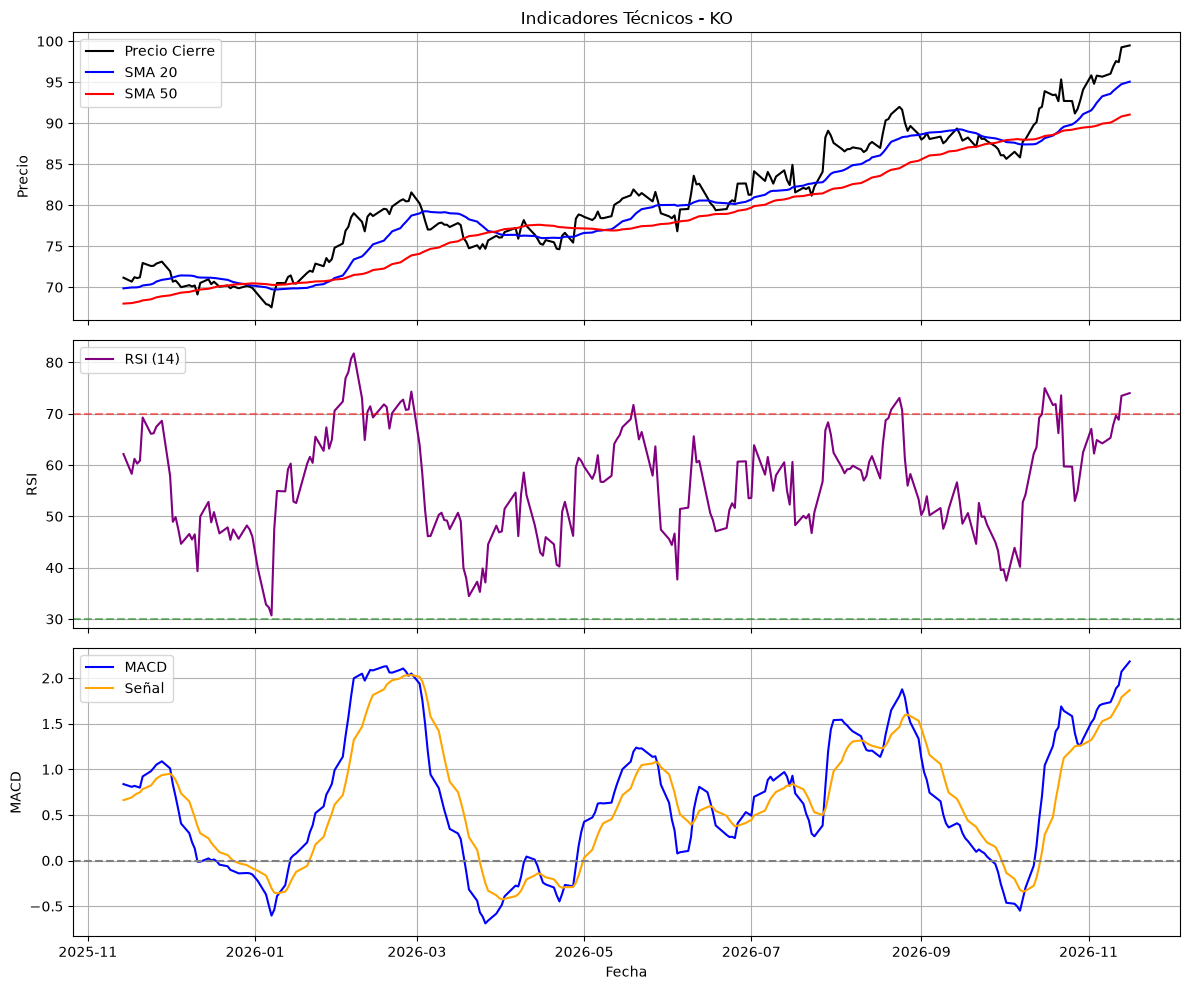


Generando gráficos para: ABBV


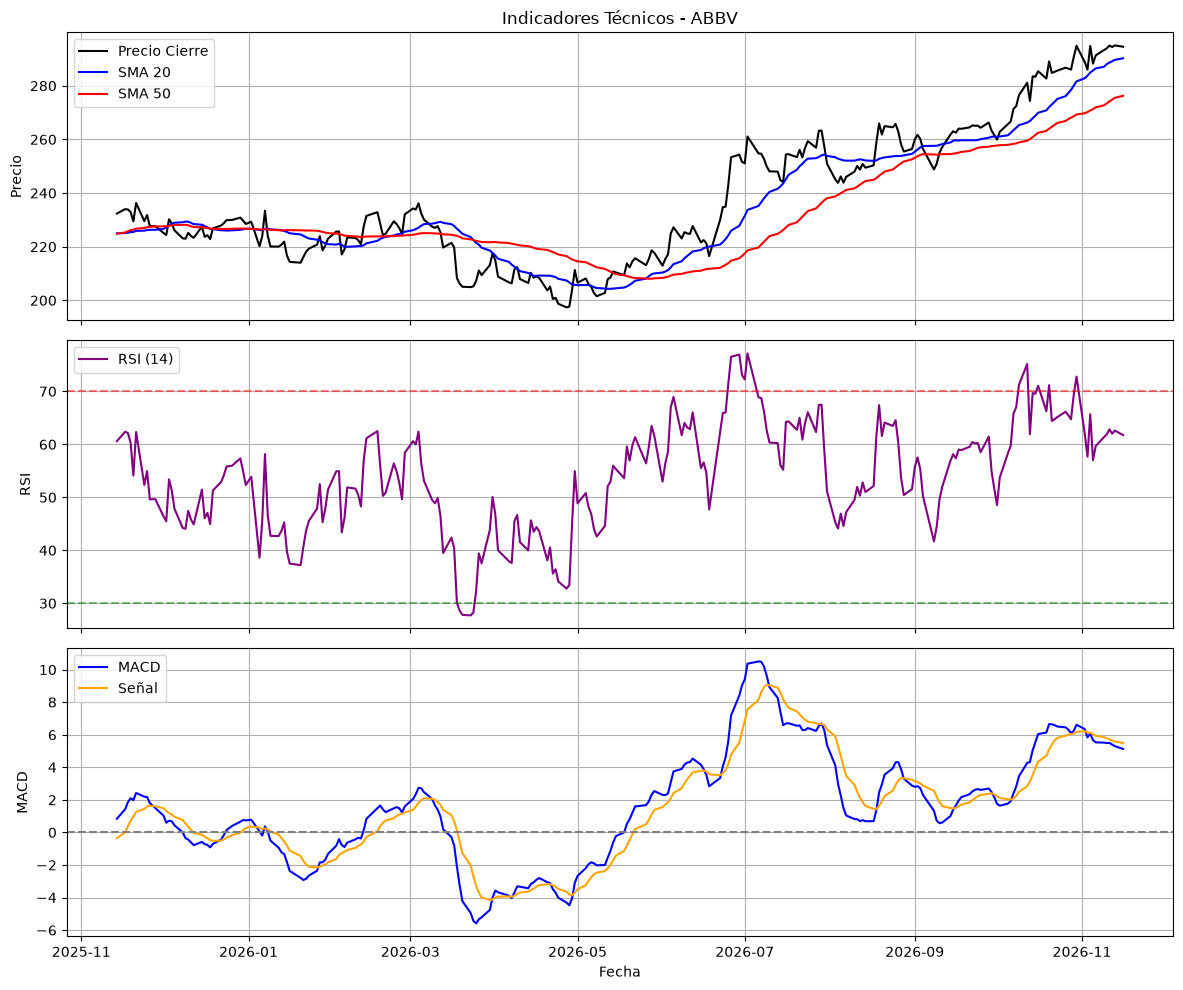


Generando gráficos para: XOM


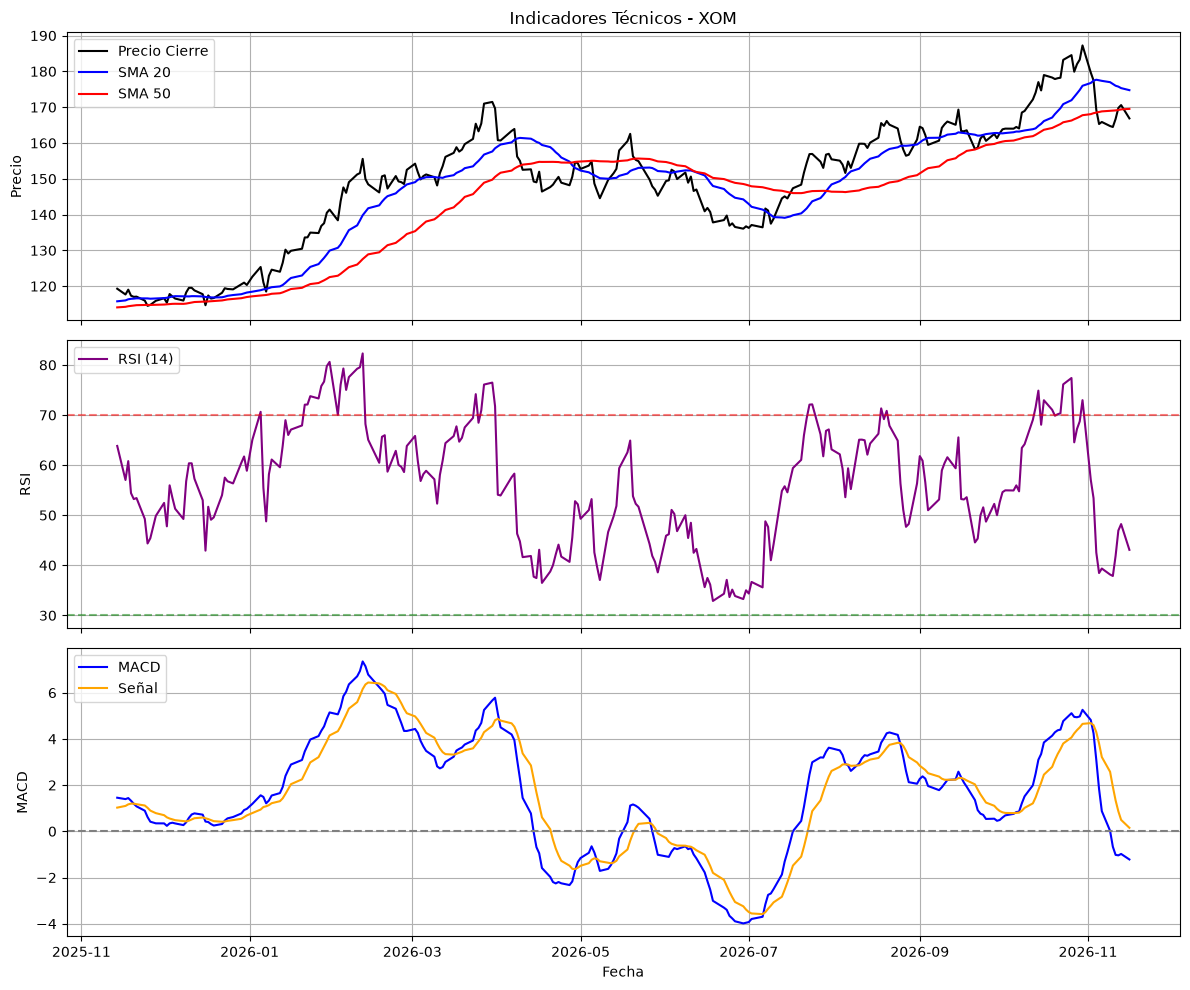

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

print("=" * 70)
print("          ANÁLISIS TÉCNICO DETALLADO: TOP 5 ACCIONES")
print("=" * 70)

for ticker in top_tickers:
    print(f"\nGenerando gráficos para: {ticker.upper()}")

    # Preparar los datos
    df_tec = acciones_validas[ticker].copy()
    df_tec['Date'] = pd.to_datetime(df_tec['Date'])
    df_tec = df_tec.set_index('Date').sort_index()

    # 1. Medias Móviles Simples (SMA 20 y 50)
    df_tec['SMA_20'] = df_tec['Close'].rolling(window=20).mean()
    df_tec['SMA_50'] = df_tec['Close'].rolling(window=50).mean()

    # 2. RSI 14
    df_tec['RSI_14'] = calcular_rsi_wilder(df_tec['Close'], 14)

    # 3. MACD
    ema_12 = df_tec['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = df_tec['Close'].ewm(span=26, adjust=False).mean()
    df_tec['MACD'] = ema_12 - ema_26
    df_tec['MACD_Senal'] = df_tec['MACD'].ewm(span=9, adjust=False).mean()

    # Filtrar solo el último año bursátil para una mejor visualización (252 días)
    df_graf = df_tec.tail(252)

    # Crear la figura con 3 subgráficos
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    # Gráfico 1: Precio y Medias Móviles
    ax1.plot(df_graf.index, df_graf['Close'], label='Precio Cierre', color='black')
    ax1.plot(df_graf.index, df_graf['SMA_20'], label='SMA 20', color='blue')
    ax1.plot(df_graf.index, df_graf['SMA_50'], label='SMA 50', color='red')
    ax1.set_title(f'Indicadores Técnicos - {ticker.upper()}')
    ax1.set_ylabel('Precio')
    ax1.legend()
    ax1.grid(True)

    # Gráfico 2: RSI
    ax2.plot(df_graf.index, df_graf['RSI_14'], color='purple', label='RSI (14)')
    ax2.axhline(70, color='red', linestyle='--', alpha=0.5)
    ax2.axhline(30, color='green', linestyle='--', alpha=0.5)
    ax2.set_ylabel('RSI')
    ax2.legend(loc='upper left')
    ax2.grid(True)

    # Gráfico 3: MACD
    ax3.plot(df_graf.index, df_graf['MACD'], color='blue', label='MACD')
    ax3.plot(df_graf.index, df_graf['MACD_Senal'], color='orange', label='Señal')
    ax3.axhline(0, color='gray', linestyle='--')
    ax3.set_ylabel('MACD')
    ax3.set_xlabel('Fecha')
    ax3.legend(loc='upper left')
    ax3.grid(True)

    plt.tight_layout()
    plt.show()